Algoritmos Genéticos (GA)

Importaciones y configuraciones

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from deap import algorithms
from deap import base
from deap import creator
from deap import tools
from sklearn import linear_model
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

Primera fase: Generación del dataset y creación de la función de evaluación

In [2]:
# Definimos la cantidad de features a utilizar
n_features = 15
# Seteamos verbose en false
verbose = 0
# Generaramos el dataset
X, y = make_classification(n_samples=1000, n_features=n_features, n_classes=2, n_informative=4,
n_redundant=1, n_repeated=2, random_state=1)
# Instanciamos el model
model = linear_model.LogisticRegression()

In [3]:
def calculate_fitness(model, x, y):
    cv_set = np.repeat(-1.0, x.shape[0])
    skf = StratifiedKFold(n_splits=5)
    for train_index, test_index in skf.split(x, y):
        x_train, x_test = x[train_index], x[test_index]
        y_train, y_test = y[train_index], y[test_index]
        if x_train.shape[0] != y_train.shape[0]:
            raise Exception()
        model.fit(x_train, y_train)
        predicted_y = model.predict(x_test)
        cv_set[test_index] = predicted_y
    return f1_score(y,cv_set)

def evaluate(individual):
    np_ind = np.asarray(individual)
    if np.sum(np_ind) == 0:
        fitness = 0.0
    else:
        feature_idx = np.where(np_ind == 1)[0]
        fitness = calculate_fitness(
        model, X[:, feature_idx], y
        )
    if verbose:
        print("Individuo: {} Fitness Score: {} ".format(individual, fitness))
    return (fitness,)

Segunda fase: Instanciación del toolbox de DEAP y configuración del problema y los operadores.

In [4]:
creator.create("FeatureSelect", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FeatureSelect)
toolbox = base.Toolbox()

toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n_features)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

toolbox.register("mate", tools.cxTwoPoint) # Crossover
toolbox.register("mutate", tools.mutFlipBit, indpb=0.1) # Mutacion
toolbox.register("select", tools.selTournament, tournsize=3) # Selecion
toolbox.register("evaluate", evaluate) # Evaluacion

Tercera fase: Generación de un Algoritmo Genético Simple.

In [5]:
N_POP = 100 # Tamaño de la población
CXPB = 0.5 # Probabilidad de crossover
MUTPB = 0.2 # Probabilidad de mutación
NGEN = 10 # Cantidad de generaciones
print("Tamaño población: {}\nProbabilidad de crossover: {}\nProbabilida de mutación: {}\nGeneraciones totales: {}".format(N_POP, CXPB, MUTPB, NGEN))

# Función para generar salidas con estadisticas de cada generacion
def build_stats(gen, pop, fits):
    record = {}
    length = len(pop)
    mean = sum(fits) / length
    sum2 = sum(x * x for x in fits)
    std = abs(sum2 / length - mean ** 2) ** 0.5
    record['gen'] = gen + 1
    record['min'] = min(fits)
    record['max'] = max(fits)
    record['avg'] = mean
    record['std'] = std
    print(" Min {} Max {} Avg {} Std {}".format(min(fits), max(fits), mean, std))
    return record

Tamaño población: 100
Probabilidad de crossover: 0.5
Probabilida de mutación: 0.2
Generaciones totales: 10


In [6]:
# Inicializamos a la poblacion
pop = toolbox.population(N_POP)
print("Evaluamos a los individuos inicializados.......")
fitnesses = list(map(toolbox.evaluate, pop))
# Asignamos a los inviduos el score del paso anterior
for ind, fit in zip(pop, fitnesses):
    ind.fitness.values = fit
fitness_in_generation = {} # Variable auxiliar para generar el reporte
stats_records = [] # Variable auxiliar para generar el reporte

print("-- GENERACIÓN 0 --")
stats_records.append(build_stats(-1, pop, [f[0] for f in fitnesses]))

for g in range(NGEN):
    print("-- GENERACIÓN {} --".format(g + 1))
    # Seleccionamos a la siguiente generacion de individuos
    offspring = toolbox.select(pop, len(pop))
    # Clonamos a los invidiuos seleccionados
    offspring = list(map(toolbox.clone, offspring))
    # Aplicamos crossover y mutacion a los inviduos seleccionados
    for child1, child2 in zip(offspring[::2], offspring[1::2]):
        if random.random() < CXPB:
            toolbox.mate(child1, child2)
            del child1.fitness.values
            del child2.fitness.values
            
    for mutant in offspring:
        if random.random() < MUTPB:
            toolbox.mutate(mutant)
            del mutant.fitness.values

    # Evaluamos a los individuos con una fitness invalida
    weak_ind = [ind for ind in offspring if not ind.fitness.valid]
    fitnesses = list(map(toolbox.evaluate, weak_ind))
    for ind, fit in zip(weak_ind, fitnesses):
        ind.fitness.values = fit
    print("Individuos evaluados: {}".format(len(weak_ind)))
    # Reemplazamos a la poblacion completamente por los nuevos descendientes
    pop[:] = offspring
    # Mostramos las salidas de la estadisticas de la generacion actual
    fits = [ind.fitness.values[0] for ind in pop]
    stats_records.append(build_stats(g, pop, fits))

Evaluamos a los individuos inicializados.......


-- GENERACIÓN 0 --
 Min 0.484472049689441 Max 0.806640625 Avg 0.7402259288620658 Std 0.0822124023872887
-- GENERACIÓN 1 --


Individuos evaluados: 53
 Min 0.5596707818930041 Max 0.806640625 Avg 0.7769031325870409 Std 0.04110597783609986
-- GENERACIÓN 2 --


Individuos evaluados: 51
 Min 0.6686567164179105 Max 0.806640625 Avg 0.7911436828112152 Std 0.017571951258063698
-- GENERACIÓN 3 --


Individuos evaluados: 66
 Min 0.5501066098081023 Max 0.8125 Avg 0.7900092509009289 Std 0.03122826866016653
-- GENERACIÓN 4 --


...

Individuos evaluados: 56
 Min 0.6378600823045267 Max 0.810126582278481 Avg 0.7924465614468384 Std 0.03845865101347397
-- GENERACIÓN 7 --


Individuos evaluados: 65
 Min 0.5605095541401274 Max 0.8125 Avg 0.7927736020803461 Std 0.04519904879344339
-- GENERACIÓN 8 --


Individuos evaluados: 61
 Min 0.6434426229508197 Max 0.8125 Avg 0.8018459936901405 Std 0.03137300709377096
-- GENERACIÓN 9 --


Individuos evaluados: 59
 Min 0.6489795918367347 Max 0.8125 Avg 0.8037296465236915 Std 0.02701772336749708
-- GENERACIÓN 10 --


Individuos evaluados: 62
 Min 0.6434426229508197 Max 0.8125 Avg 0.7984700425122052 Std 0.04109537147319566


/var/folders/vc/8426pvzx7dg0wyc0137xtt740000gn/T/ipykernel_5871/1450446789.py:4: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "-bo" (-> color='b'). The keyword argument will take precedence.
  plt.plot(front[:,0], front[:,1], "-bo", c="b")


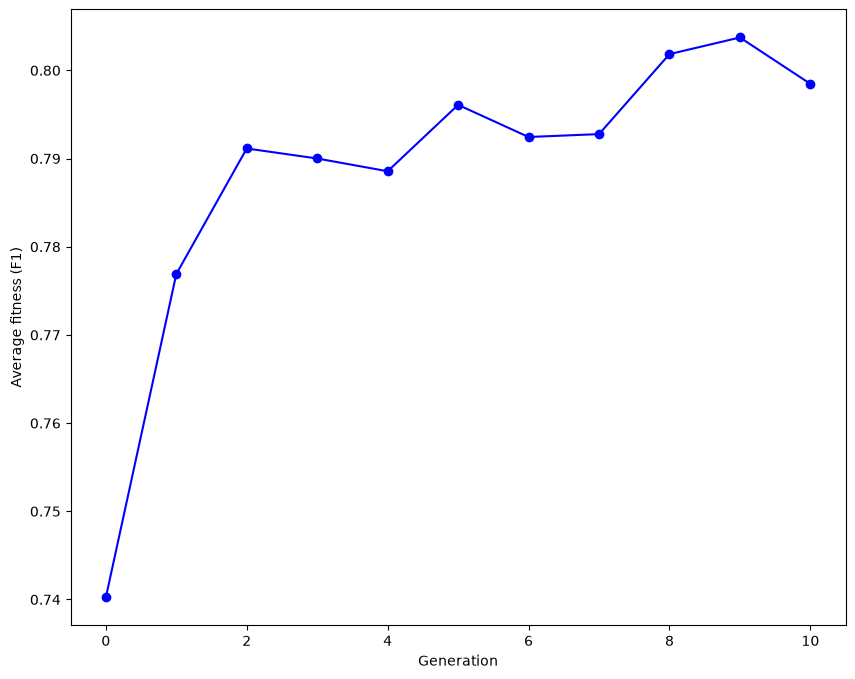

In [7]:
# Ploteamos el AVG por generacion
plt.figure(figsize=(10,8))
front = np.array([(c['gen'], c['avg']) for c in stats_records])
plt.plot(front[:,0], front[:,1], "-bo", c="b")
plt.xlabel("Generation")
plt.ylabel("Average fitness (F1)")
plt.axis("tight")
plt.show()

In [8]:
best_solution = tools.selBest(pop, 1)[0]
print(
"El mejor individuo es: \n{}, con un F1 Score de {}".format(best_solution,
best_solution.fitness.values)
)

El mejor individuo es: 
[0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1], con un F1 Score de (0.8125,)
